# Datos del Titanic

## Cargar el Dataset y limpiar datos

Ningun algoritmo puede entrenar la tabla si tenemos:

-Celdas vacías (`NaN`): No tenemos alomejor registrada la edad o camarote de ciertos pasajeros

-Palabras de texto: Columnas como `Sex` (`"male"` etc). Una ecuación matematica no puede multiplicar palabras

In [2]:
import os
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

#Descargamos el dataset oficial de Titanic (891 pasajeros) si aún no está en data/

ruta_csv = "../data/titanic.csv"
if not os.path.exists(ruta_csv):
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    df = pd.read_csv(url)
    df.to_csv(ruta_csv, index=False)
    print("Dataset descargado y guardado en ../data/titanic.csv")

else: 
    df = pd.read_csv(ruta_csv)
    print("Dataset cargado desde ../data/titanic.csv")

print(f"\nTotal de pasajeros; {df.shape[0]} filas x {df.shape[1]} columnas")
print("\n -- Conteo de datos faltants (nulos / NaN) por Columna ---")
print(df.isnull().sum())

#Vemos los primeros 5 pasajeros
df.head()

Dataset descargado y guardado en ../data/titanic.csv

Total de pasajeros; 891 filas x 12 columnas

 -- Conteo de datos faltants (nulos / NaN) por Columna ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


A 177 personas no se les conoce la edad
A 687 de los 891 pasajeros (el 77%) no se les conoce el camarote
A 2 pasajeros les falta el puerto donde subieron al barco


## Graficos Seaborn para descubrir patrones

C:\Users\Alejandro\AppData\Local\Temp\ipykernel_7020\823564868.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0], palette="Set2", errorbar=None)
C:\Users\Alejandro\AppData\Local\Temp\ipykernel_7020\823564868.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1], palette="Blues_r", errorbar=None)


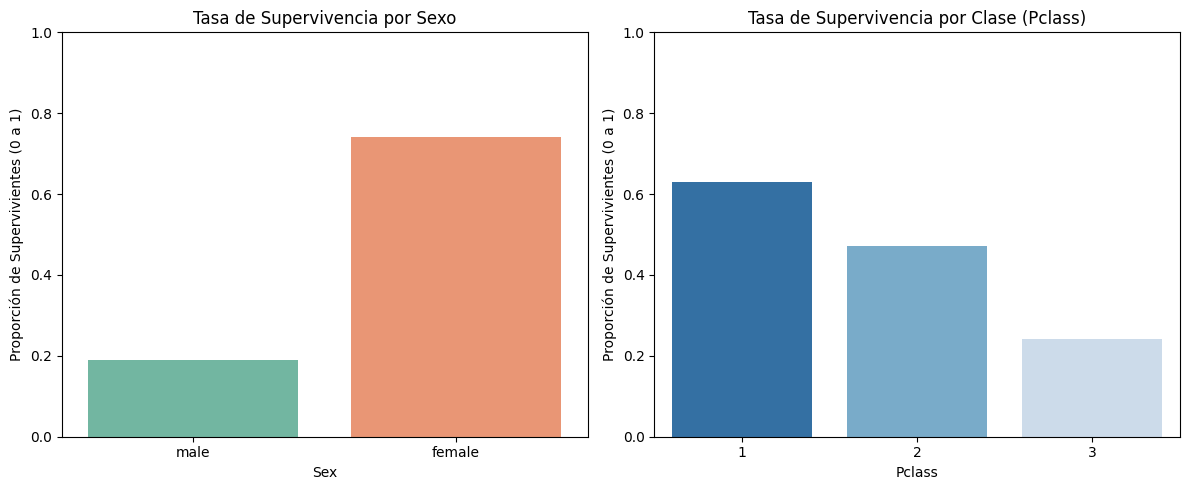

In [4]:
#Gráfico 1: Porcentaje de Supervivencia por Sexo y por Clase

fig, axes = plt.subplots(1,2, figsize=(12, 5))

#Panel izquierdo: Supervivencia por Sexo

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0], palette="Set2", errorbar=None)
axes[0].set_title("Tasa de Supervivencia por Sexo")
axes[0].set_ylabel("Proporción de Supervivientes (0 a 1)")
axes[0].set_ylim(0, 1)

# Panel derecho: Supervivencia por Clase del Billete
sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1], palette="Blues_r", errorbar=None)
axes[1].set_title("Tasa de Supervivencia por Clase (Pclass)")
axes[1].set_ylabel("Proporción de Supervivientes (0 a 1)")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig("../reports/figures/01_supervivencia_sexo_clase.png", dpi=150, bbox_inches="tight")
plt.show()